In [1]:
import rebound
import numpy as np
import matplotlib.pyplot as plt 

In [2]:
sim = rebound.Simulation()
sim.integrator = "ias15"
sim.units = ("AU", "yr", "Msun")

In [3]:
sim.add(m=1.0, r=0.00465047)
sim.add(m=1e-3, a=5.2, e=0, r=0.0000477895)
sim.add(m=3e-4, a=9.54, e=0, r=0.0000403)
sim.move_to_com()

In [4]:
sim.integrate(0.0)
sim.widget(size=(950,950))

RuntimeError: Error binding to port 1234. Port might be in use.


In [5]:
Num = 100000
times = np.linspace(0., 1000000., Num)
a1 = []
e1 = []
t1 = []
a2 = []
e2 = []

E0 = sim.energy()
Lx0, Ly0, Lz0 = sim.angular_momentum()
L0 = np.sqrt(Lx0**2 + Ly0**2 + Lz0**2)

err_ener=[]
err_ang=[]

for i, t in enumerate(times):
    sim.integrate(t, exact_finish_time=0)
    a1.append(sim.particles[1].a)
    e1.append(sim.particles[1].e)
    a2.append(sim.particles[2].a)
    e2.append(sim.particles[2].e)
    t1.append(sim.t)

    E_actual = sim.energy()
    err_ener.append(abs((E_actual - E0) / E0))

    Lx, Ly, Lz = sim.angular_momentum()
    L_actual = np.sqrt(Lx**2 + Ly**2 + Lz**2)
    err_ang.append(abs((L_actual - L0) / L0))

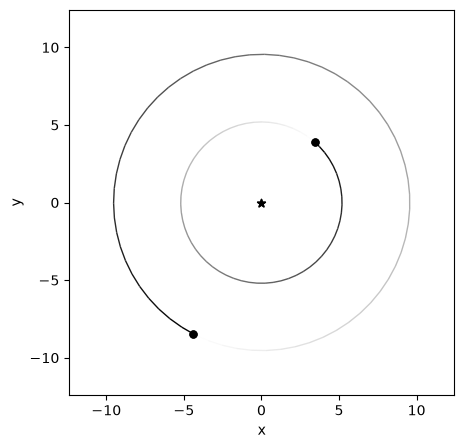

In [6]:
%matplotlib inline
op = rebound.OrbitPlot(sim)

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


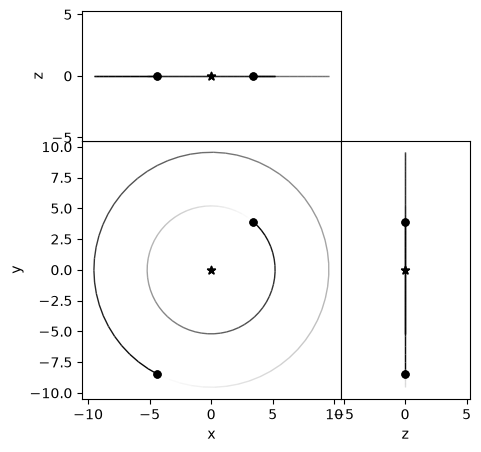

In [7]:
ops = rebound.OrbitPlotSet(sim)

In [8]:
sim.status(showAllFields=False)

---------------------------------
REBOUND version:     	5.2.2
REBOUND built on:    	Oct  5 2026 13:03:15
Number of particles: 	3
Selected integrator: 	ias15
Simulation time:     	1.0000000385677773e+06
Current timestep:    	0.314682
---------------------------------
<rebound.particle.Particle object at 0x7f1b01696d40, m=1.0 x=-0.0021105651681249072 y=-0.0013640161668574643 z=0.0 vx=0.0015291733030276008 vy=-0.0015368266052456319 vz=0.0>
<rebound.particle.Particle object at 0x7f1b00b40340, m=0.001 x=3.4255336441608186 y=3.90372699400974 z=0.0 vx=-2.0713312233603487 vy=1.8184291418050809 vz=0.0>
<rebound.particle.Particle object at 0x7f1b01696d40, m=0.0003 x=-4.383228089290468 y=-8.46570290736692 z=0.0 vx=1.80719306777608 vy=-0.9386751218650953 vz=0.0>
---------------------------------


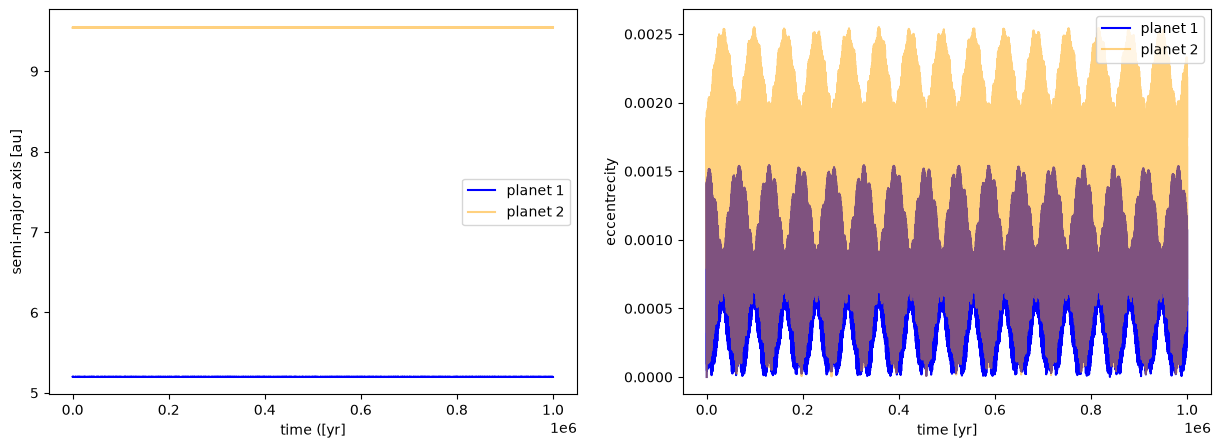

In [9]:
fig = plt.figure(figsize=(15,5))

ax = plt.subplot(121)
ax.set_xlabel("time ([yr]")
ax.set_ylabel("semi-major axis [au]")
# ax.set_ylabel("err_ener")
plt.plot(t1, a1, color="blue", label="planet 1")
plt.plot(t1, a2, color="orange", alpha=0.5, label="planet 2")
# plt.plot(t1, err_ener, color="blue", label="planet 1")
ax.legend(loc="best")

ax = plt.subplot(122)
ax.set_xlabel("time [yr]")
ax.set_ylabel("eccentrecity")
# ax.set_ylabel("err_ang")
plt.plot(t1, e1, color="blue", label="planet 1")
plt.plot(t1, e2, color="orange", alpha=0.5, label="planet 2")
# plt.plot(t1, err_ang, color="blue", label="planet 1")
ax.legend(loc="best")

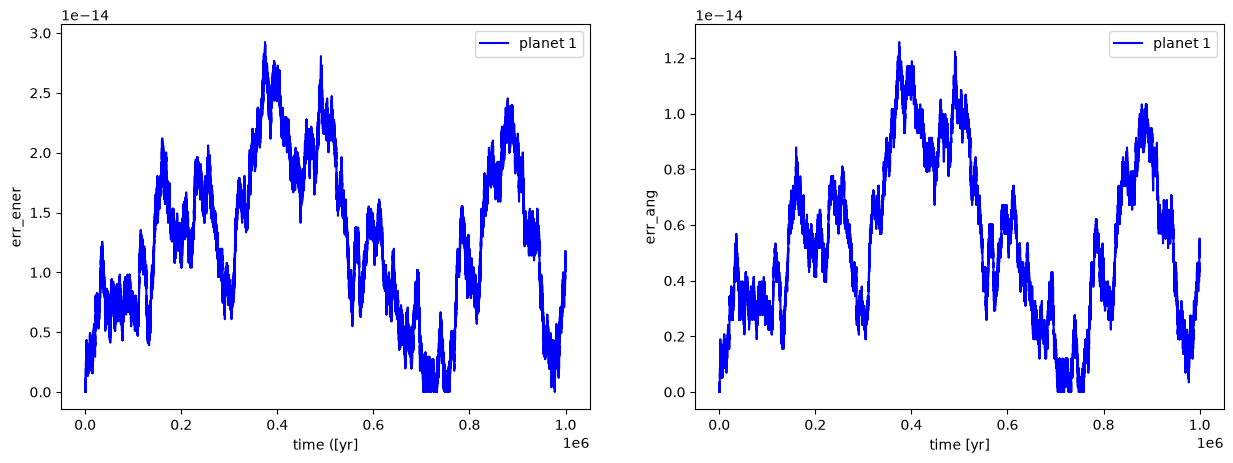

In [11]:
fig = plt.figure(figsize=(15,5))

ax = plt.subplot(121)
ax.set_xlabel("time ([yr]")
ax.set_ylabel("err_ener")
plt.plot(t1, err_ener, color="blue", label="planet 1")
ax.legend(loc="best")

ax = plt.subplot(122)
ax.set_xlabel("time [yr]")
ax.set_ylabel("err_ang")
plt.plot(t1, err_ang, color="blue", label="planet 1")
ax.legend(loc="best")